In [4]:
pip install scikit-Learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 1.4 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.4 MB 1.3 MB/s eta 0:00:06
   ------ --------------------------------- 1.3/8.4 MB 1.3 MB/s eta 0:00:06
   ------ --------------------------------- 1.3/8.4 MB 1.3 MB/s eta 0:00:06
   -------- ------------------------------- 1.8/8.4 MB 1.3 MB/s eta 0:00:05
   ---------- ----------------------------- 2.1/8.4 MB 1.4 MB/s eta 0:00:05
   ----------- ---------------------------- 2.4/8.4 MB 1.4 MB/s eta 0:00:05
   ------------- -------------------------- 2.9/8.4 MB 1.4 MB/s eta 0:00:04
   --------------- ------------------------ 3.1/8.4 MB 1.5 MB/s eta 0:00:04
   ---------------- ----------------------- 3.4/8.4 MB 1.5 MB/s eta 0:00:04
   ----------------- ------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
#==============================================================
# PROJECT STATEMENT : BUILDING A LINEAR REGRESSION MODEL TO 
# PREDICT TEMPERATURE SWINGS USING HISTORICAL DATA (2020-2024)
#==============================================================



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ModuleNotFoundError: No module named 'sklearn'

In [ ]:
# ------------------------------------------
# STEP 1: Load and Clean the Dataset
# ------------------------------------------
print("Reading the data and cleaning dataset...")

df = pd.read_csv('climate_change_dataset.csv')

numeric_cols = [
    'Year', 'Month', 'Avg_Temp (°C)', 'Max_Temp (°C)', 'Min_Temp (°C)', 
    'Precipitation (mm)', 'Humidity (%)', 'Wind_Speed (m/s)', 
    'Solar_Irradiance (W/m²)', 'Cloud_Cover (%)', 'CO2_Concentration (ppm)', 
    'Altitude (m)', 'Proximity_to_Water (km)', 'Urbanization_Index', 
    'Vegetation_Index', 'ENSO_Index', 'Particulate_Matter (µg/m³)', 'Sea_Surface_Temp (°C)'
]

# PART 1: Convert to string first to catch string-based placeholders like '99999.0', 'nan', 'Unknown'
for col in numeric_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace(['Unknown', '99999', '99999.0', 'nan', 'NaN', 'NAN', ''], np.nan)
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Filter for the target historical range (2020-2024)
df_filtered = df[(df['Year'] >= 2020) & (df['Year'] <= 2024)].copy()

# Drop rows missing critical temp values first
df_filtered = df_filtered.dropna(subset=['Max_Temp (°C)', 'Min_Temp (°C)'])

# Create the target variable: Temperature Swing (Max Temp - Min Temp)
df_filtered['Temp_Swing'] = df_filtered['Max_Temp (°C)'] - df_filtered['Min_Temp (°C)']

# PART 2: Drop logical anomalies where Min Temp > Max Temp (removes negative swings)
df_filtered = df_filtered[df_filtered['Temp_Swing'] >= 0]

print(f"Cleaned dataset rows ready: {len(df_filtered)}")

Reading the data and cleaning dataset...
Cleaned dataset rows ready: 28



--- Step 2: Exploratory Data Analysis ---
       Avg_Temp (°C)  Temp_Swing  Humidity (%)  Wind_Speed (m/s)
count      26.000000   28.000000     24.000000         25.000000
mean       13.875042   16.637959     72.456966          9.477980
std        11.591070   10.105075     19.744156          4.287026
min        -4.965473    2.552639     30.871082          0.308558
25%         5.363473    8.229316     58.526973          6.659816
50%        10.668085   17.243095     76.053732         10.648246
75%        24.672165   24.217930     86.401957         12.836511
max        34.282303   45.255766     98.056363         14.969325


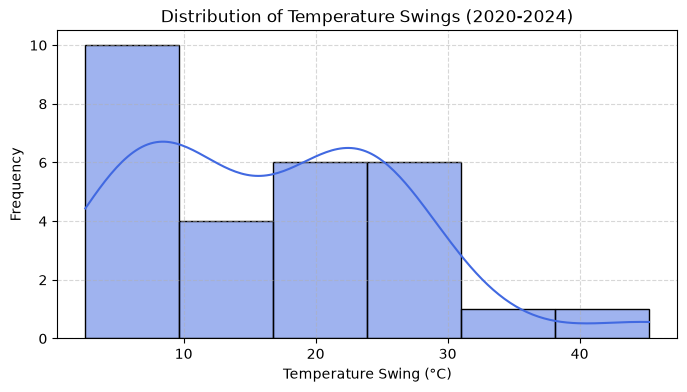

In [ ]:
# ------------------------------------------
# STEP 2: Exploratory Data Analysis (EDA)
# ------------------------------------------
print("\n--- Step 2: Exploratory Data Analysis ---")

# Display basic statistical summary of the dataset
print(df_filtered[['Avg_Temp (°C)', 'Temp_Swing', 'Humidity (%)', 'Wind_Speed (m/s)']].describe())

# Plot distribution of Temperature Swings
plt.figure(figsize=(8, 4))
sns.histplot(df_filtered['Temp_Swing'], kde=True, color='royalblue')
plt.title('Distribution of Temperature Swings (2020-2024)')
plt.xlabel('Temperature Swing (°C)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# ------------------------------------------
# STEP 3: Feature Selection & Preparation
# ------------------------------------------
print("\n--- Step 3: Preparing Features for Model ---")

# Select independent feature columns that have robust numerical data
feature_cols = [
    'Solar_Irradiance (W/m²)', 
    'Cloud_Cover (%)', 
    'Humidity (%)', 
    'Wind_Speed (m/s)', 
    'Urbanization_Index'
]

# Drop rows where selected features contain NaN values
model_df = df_filtered.dropna(subset=feature_cols + ['Temp_Swing']).copy()

X = model_df[feature_cols]
y = model_df['Temp_Swing']

print(f"Dataset samples that are used for training: {len(model_df)}")


-- Step 3: Preparing Features for Model --
Dataset samples used for training: 18


In [ ]:
# ------------------------------------------
# STEP 4: Train-Test Split & Model Training
# ------------------------------------------
print("\n--- Step 4: Training Linear Regression Model ---")

# Split data into 80% Training and 20% Testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Display model coefficients
coefficients = pd.DataFrame(lr_model.coef_, X.columns, columns=['Coefficient'])
print("\nModel Feature Coefficients:")
print(coefficients)


--- Step 4: Training Linear Regression Model ---

Model Feature Coefficients:
                         Coefficient
Solar_Irradiance (W/m²)     0.073895
Cloud_Cover (%)             0.078221
Humidity (%)               -0.211972
Wind_Speed (m/s)            0.569218
Urbanization_Index        -17.489408



--- Step 5: Model Evaluation ---
R² Score: -4.0940
Mean Absolute Error (MAE): 13.5396
Root Mean Squared Error (RMSE): 14.6063


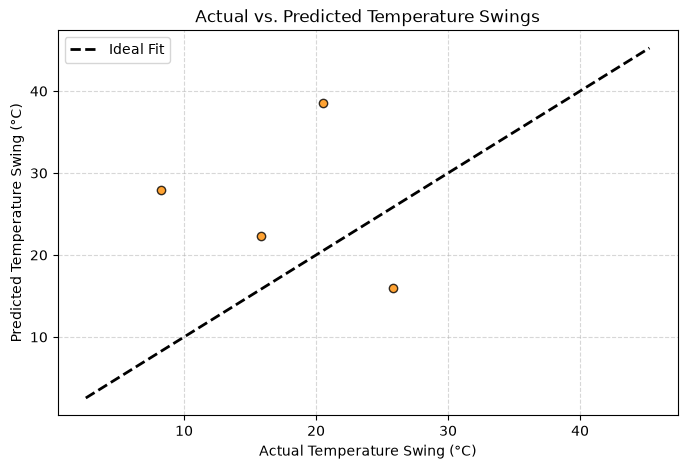

In [ ]:
# ------------------------------------------
# STEP 5: Model Evaluation
# ------------------------------------------
print("\n--- Step 5: Model Evaluation ---")

# Predict on the test set
y_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# Plot Actual vs Predicted Temperature Swings
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='darkorange', edgecolors='black', alpha=0.8)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2, label='Ideal Fit')
plt.title('Actual vs. Predicted Temperature Swings')
plt.xlabel('Actual Temperature Swing (°C)')
plt.ylabel('Predicted Temperature Swing (°C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.
